# 02 — Robustness Training Pipeline Validation

## Robustness-Enhanced Vision-Language-Action Learning

**Module:** Deep Learning (`CT100-3-M-DL`)  
**Programme:** Master in Artificial Intelligence  
**Framework:** Hugging Face LeRobot `v0.6.1`  
**Benchmark:** LIBERO-Spatial  
**Reference policy:** `lerobot/smolvla_libero`  
**Controlled fine-tuning initialization:** `lerobot/smolvla_base`

---

### Notebook objective

Notebook 00 established the dataset and benchmark foundation. Notebook 01 reproduced the released LIBERO SmolVLA policy and completed the closed-loop G0 compatibility gate.

This notebook validates the **training pipeline** required for the controlled robustness study.

A clean `Run All` performs the following sequence:

1. verify prior notebook gates,
2. freeze and validate the episode-level split,
3. pin the common SmolVLA base checkpoint,
4. verify the official LeRobot training interface,
5. run or reuse a **5-step M1 back-propagation smoke test**,
6. run or reuse a **5-step M2-E environmental-augmentation smoke test**,
7. create the complete deterministic L0–L3 language perturbation specification,
8. save experiment manifests and a final notebook PASS/FAIL summary.

The smoke tests validate the implementation path; they are **not final model training**. Hyperparameter tuning and full multi-seed training belong to Notebook 03.

> **Execution design:** no manual run switches are required. Existing valid smoke-test artifacts are reused automatically; incomplete artifacts are archived and regenerated.

## 1. Experimental design

| Model | Role | Initialization | Controlled change |
|---|---|---|---|
| M0 | Released reference | `lerobot/smolvla_libero` | No training in this study |
| M1 | Standard fine-tuning baseline | `lerobot/smolvla_base` | Original demonstrations |
| M2-L | Language robustness | `lerobot/smolvla_base` | L0 + L1 + L2 instruction variants |
| M2-E | Environmental robustness | `lerobot/smolvla_base` | Photometric visual augmentation |
| M2-LE | Combined robustness | `lerobot/smolvla_base` | Language + environmental augmentation |

**Held-out language condition:** L3 is defined but excluded from training so that later evaluation can measure transfer to an unseen perturbation category.

## 2. Environment, paths and reproducibility configuration

In [2]:
import os

os.environ.setdefault("GALLIUM_DRIVER", "d3d12")
os.environ.setdefault("MESA_D3D12_DEFAULT_ADAPTER_NAME", "NVIDIA")
os.environ.setdefault("MUJOCO_GL", "glfw")

from pathlib import Path
from datetime import datetime
import hashlib
import json
import re
import shlex
import shutil
import subprocess
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

SEED = 42
SMOKE_STEPS = 5
SMOKE_BATCH_SIZE = 1

DATASET_REPO_ID = "lerobot/libero"
BASE_MODEL_REPO_ID = "lerobot/smolvla_base"
REFERENCE_MODEL_REPO_ID = "lerobot/smolvla_libero"
LIBERO_SUITE = "libero_spatial"
VIDEO_BACKEND = "pyav"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def find_repo_root(start: Path) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if (candidate / ".git").exists():
            return candidate
    if current.name == "notebooks":
        return current.parent
    return current

REPO_ROOT = find_repo_root(Path.cwd())

CONFIG_DIR = REPO_ROOT / "configs"
SPLIT_DIR = CONFIG_DIR / "splits"
EXPERIMENT_CONFIG_DIR = CONFIG_DIR / "experiments"

RESULTS_DIR = REPO_ROOT / "results"
METRICS_DIR = RESULTS_DIR / "metrics" / "robustness_training"
FIGURES_DIR = RESULTS_DIR / "figures" / "robustness_training"
TRAIN_OUTPUT_DIR = REPO_ROOT / "experiments" / "training"

for directory in [
    SPLIT_DIR,
    EXPERIMENT_CONFIG_DIR,
    METRICS_DIR,
    FIGURES_DIR,
    TRAIN_OUTPUT_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

def git_sha(repo_root: Path):
    try:
        return subprocess.check_output(
            ["git", "rev-parse", "HEAD"],
            cwd=repo_root,
            text=True,
        ).strip()
    except Exception:
        return None

PROJECT_GIT_SHA = git_sha(REPO_ROOT)

environment_summary = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "device": DEVICE,
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "project_git_sha": PROJECT_GIT_SHA,
}

display(pd.DataFrame([environment_summary]).T.rename(columns={0: "Value"}))

if not torch.cuda.is_available():
    warnings.warn(
        "CUDA is unavailable. The notebook remains logically valid, "
        "but SmolVLA smoke training will be much slower on CPU."
    )

,Value
python,3.12.14
torch,2.11.0+cu128
cuda_available,True
device,cuda
gpu,NVIDIA GeForce RTX 5090
project_git_sha,c72dced819f45299ca35a50b1a7ba479d07f945e


## 3. Verify Notebook 00 and Notebook 01 gates

In [3]:
NOTEBOOK00_SUMMARY = (
    REPO_ROOT
    / "results"
    / "metrics"
    / "dataset_eda"
    / "dataset_eda_summary.json"
)

NOTEBOOK01_SUMMARY = (
    REPO_ROOT
    / "results"
    / "metrics"
    / "baseline_reproduction"
    / "baseline_reproduction_summary.json"
)

assert NOTEBOOK00_SUMMARY.exists(), (
    f"Missing Notebook 00 summary: {NOTEBOOK00_SUMMARY}"
)
assert NOTEBOOK01_SUMMARY.exists(), (
    f"Missing Notebook 01 summary: {NOTEBOOK01_SUMMARY}"
)

with open(NOTEBOOK00_SUMMARY, "r") as f:
    notebook00_summary = json.load(f)

with open(NOTEBOOK01_SUMMARY, "r") as f:
    notebook01_summary = json.load(f)

prior_gate = {
    "Notebook 00 dataset audit":
        bool(notebook00_summary["dataset_audit_pass"]),
    "Notebook 01 G0 closed-loop compatibility":
        bool(notebook01_summary["g0_pass"]),
    "Dataset repository":
        notebook00_summary["dataset_repo_id"] == DATASET_REPO_ID,
    "LIBERO suite":
        notebook00_summary["suite"] == LIBERO_SUITE,
}

display(
    pd.DataFrame(
        [{"check": key, "pass": value} for key, value in prior_gate.items()]
    )
)

assert all(prior_gate.values()), (
    "Notebook 02 requires Notebook 00 dataset audit PASS and Notebook 01 G0 PASS."
)

DATASET_REVISION = notebook00_summary["dataset_revision"]
REFERENCE_MODEL_REVISION = notebook01_summary["model_revision"]

print("PRIOR NOTEBOOK GATES: PASS")
print("Dataset revision        :", DATASET_REVISION)
print("Reference model revision:", REFERENCE_MODEL_REVISION)

,check,pass
0,Notebook 00 dataset audit,True
1,Notebook 01 G0 closed-loop compatibility,True
2,Dataset repository,True
3,LIBERO suite,True


PRIOR NOTEBOOK GATES: PASS
Dataset revision        : a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4
Reference model revision: 31d453f7edd78c839a8bbc39744a292686daf0de


## 4. Freeze and validate the LIBERO-Spatial episode split

Notebook 00 created an episode-level stratified split. Notebook 02 freezes that artifact as `v1`.

The split is immutable for M1/M2 comparisons:

- **346 training episodes**
- **86 validation episodes**
- no episode overlap
- all 10 LIBERO-Spatial tasks represented in both subsets

A SHA-256 digest is stored so accidental edits can be detected later.

In [4]:
candidate_split_path = (
    SPLIT_DIR / f"libero_spatial_split_candidate_seed{SEED}.csv"
)

frozen_split_path = (
    SPLIT_DIR / f"libero_spatial_split_v1_seed{SEED}.csv"
)

assert candidate_split_path.exists() or frozen_split_path.exists(), (
    "Neither the candidate nor frozen LIBERO-Spatial split exists. "
    "Run Notebook 00 first."
)

if not frozen_split_path.exists():
    shutil.copy2(candidate_split_path, frozen_split_path)
    print("Frozen split created:", frozen_split_path)
else:
    print("Frozen split found   :", frozen_split_path)

frozen_split_df = pd.read_csv(frozen_split_path)

required_split_columns = {
    "episode_index",
    "task_index",
    "task_instruction",
    "n_frames",
    "split",
}

missing = required_split_columns - set(frozen_split_df.columns)
assert not missing, f"Frozen split missing columns: {sorted(missing)}"

frozen_split_df["split"] = (
    frozen_split_df["split"]
    .astype(str)
    .str.lower()
    .str.strip()
    .replace({"val": "validation", "valid": "validation"})
)

assert set(frozen_split_df["split"]) == {"train", "validation"}
assert frozen_split_df["episode_index"].is_unique

train_ids = sorted(
    frozen_split_df.loc[
        frozen_split_df["split"] == "train",
        "episode_index",
    ].astype(int).tolist()
)

validation_ids = sorted(
    frozen_split_df.loc[
        frozen_split_df["split"] == "validation",
        "episode_index",
    ].astype(int).tolist()
)

assert set(train_ids).isdisjoint(validation_ids)

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

FROZEN_SPLIT_SHA256 = sha256_file(frozen_split_path)

split_summary = {
    "train_episodes": len(train_ids),
    "validation_episodes": len(validation_ids),
    "total_episodes": len(frozen_split_df),
    "episode_overlap": len(set(train_ids).intersection(validation_ids)),
    "train_frames": int(
        frozen_split_df.loc[
            frozen_split_df["split"] == "train",
            "n_frames",
        ].sum()
    ),
    "validation_frames": int(
        frozen_split_df.loc[
            frozen_split_df["split"] == "validation",
            "n_frames",
        ].sum()
    ),
    "split_sha256": FROZEN_SPLIT_SHA256,
}

display(pd.DataFrame([split_summary]).T.rename(columns={0: "Value"}))

assert split_summary["train_episodes"] == 346
assert split_summary["validation_episodes"] == 86
assert split_summary["episode_overlap"] == 0

Frozen split found   : /home/leeming/projects/deep-learning-vla-robustness/configs/splits/libero_spatial_split_v1_seed42.csv


,Value
train_episodes,346
validation_episodes,86
total_episodes,432
episode_overlap,0
train_frames,42156
validation_frames,10814
split_sha256,0d13554df26d28cfefd58a4d0d873839d54109a4b494f5...


### Task coverage

In [5]:
task_balance_df = (
    frozen_split_df
    .groupby(
        ["task_index", "task_instruction", "split"],
        as_index=False,
    )
    .agg(episodes=("episode_index", "nunique"))
    .sort_values(["task_index", "split"])
    .reset_index(drop=True)
)

display(task_balance_df)

train_task_ids = set(
    frozen_split_df.loc[
        frozen_split_df["split"] == "train",
        "task_index",
    ].astype(int)
)

validation_task_ids = set(
    frozen_split_df.loc[
        frozen_split_df["split"] == "validation",
        "task_index",
    ].astype(int)
)

all_task_ids = set(frozen_split_df["task_index"].astype(int))

assert len(all_task_ids) == 10
assert train_task_ids == all_task_ids
assert validation_task_ids == all_task_ids

spatial_original_tasks_df = (
    frozen_split_df[
        ["task_index", "task_instruction"]
    ]
    .drop_duplicates()
    .sort_values("task_index")
    .reset_index(drop=True)
)

assert len(spatial_original_tasks_df) == 10

print("FROZEN SPLIT TASK COVERAGE: PASS")
display(spatial_original_tasks_df)

,task_index,task_instruction,split,episodes
0,30,pick up the black bowl next to the cookie box ...,train,37
1,30,pick up the black bowl next to the cookie box ...,validation,9
2,31,pick up the black bowl in the top drawer of th...,train,34
3,31,pick up the black bowl in the top drawer of th...,validation,8
4,32,pick up the black bowl on the ramekin and plac...,train,31
5,32,pick up the black bowl on the ramekin and plac...,validation,8
6,33,pick up the black bowl on the stove and place ...,train,28
7,33,pick up the black bowl on the stove and place ...,validation,7
8,34,pick up the black bowl between the plate and t...,train,36
9,34,pick up the black bowl between the plate and t...,validation,9


FROZEN SPLIT TASK COVERAGE: PASS


,task_index,task_instruction
0,30,pick up the black bowl next to the cookie box ...
1,31,pick up the black bowl in the top drawer of th...
2,32,pick up the black bowl on the ramekin and plac...
3,33,pick up the black bowl on the stove and place ...
4,34,pick up the black bowl between the plate and t...
5,35,pick up the black bowl on the cookie box and p...
6,36,pick up the black bowl next to the plate and p...
7,37,pick up the black bowl next to the ramekin and...
8,38,pick up the black bowl from table center and p...
9,39,pick up the black bowl on the wooden cabinet a...


## 5. Pin the common SmolVLA base checkpoint

In [6]:
from huggingface_hub import HfApi, snapshot_download

hf_api = HfApi()
base_model_info = hf_api.model_info(BASE_MODEL_REPO_ID)
BASE_MODEL_REVISION = base_model_info.sha

assert BASE_MODEL_REVISION

BASE_MODEL_SNAPSHOT = Path(
    snapshot_download(
        repo_id=BASE_MODEL_REPO_ID,
        revision=BASE_MODEL_REVISION,
    )
)

with open(BASE_MODEL_SNAPSHOT / "config.json", "r") as f:
    base_config = json.load(f)

base_model_summary = {
    "repo_id": BASE_MODEL_REPO_ID,
    "revision": BASE_MODEL_REVISION,
    "chunk_size": base_config.get("chunk_size"),
    "n_action_steps": base_config.get("n_action_steps"),
    "optimizer_lr": base_config.get("optimizer_lr"),
    "optimizer_weight_decay": base_config.get("optimizer_weight_decay"),
    "scheduler_warmup_steps": base_config.get("scheduler_warmup_steps"),
    "scheduler_decay_steps": base_config.get("scheduler_decay_steps"),
    "freeze_vision_encoder": base_config.get("freeze_vision_encoder"),
    "train_expert_only": base_config.get("train_expert_only"),
    "train_state_proj": base_config.get("train_state_proj"),
}

display(pd.DataFrame([base_model_summary]).T.rename(columns={0: "Value"}))

print("BASE MODEL PINNING: PASS")

/home/leeming/miniforge3/envs/vla-libero/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 10 files: 100%|██████████| 10/10 [00:00<00:00, 1514.03it/s]


,Value
repo_id,lerobot/smolvla_base
revision,c83c3163b8ca9b7e67c509fffd9121e66cb96205
chunk_size,50
n_action_steps,50
optimizer_lr,0.0001
optimizer_weight_decay,0.0
scheduler_warmup_steps,1000
scheduler_decay_steps,30000
freeze_vision_encoder,True
train_expert_only,True


BASE MODEL PINNING: PASS


### Feature-schema adaptation

`smolvla_base` carries the feature schema of its original pretraining data. LIBERO uses a different observation/action schema.

The training command therefore keeps the pretrained neural weights while passing:

```text
--policy.input_features null
--policy.output_features null
```

This instructs LeRobot to infer the actual feature schema from the pinned LIBERO dataset rather than forcing incompatible pretrained feature names.

## 6. Verify the LeRobot training interface and frozen subsets

In [7]:
from lerobot.configs.default import DatasetConfig
from lerobot.datasets.lerobot_dataset import LeRobotDataset

dataset_config_fields = set(DatasetConfig.__dataclass_fields__.keys())

required_training_fields = {
    "repo_id",
    "episodes",
    "revision",
    "video_backend",
    "image_transforms",
}

interface_checks = {
    field: field in dataset_config_fields
    for field in sorted(required_training_fields)
}

display(
    pd.DataFrame(
        [{"field": key, "available": value}
         for key, value in interface_checks.items()]
    )
)

assert all(interface_checks.values())

train_subset = LeRobotDataset(
    DATASET_REPO_ID,
    revision=DATASET_REVISION,
    episodes=train_ids,
    download_videos=False,
    video_backend=VIDEO_BACKEND,
)

validation_subset = LeRobotDataset(
    DATASET_REPO_ID,
    revision=DATASET_REVISION,
    episodes=validation_ids,
    download_videos=False,
    video_backend=VIDEO_BACKEND,
)

subset_summary = {
    "train_episodes_requested": len(train_ids),
    "train_episodes_loaded": int(train_subset.num_episodes),
    "train_frames_loaded": int(train_subset.num_frames),
    "validation_episodes_requested": len(validation_ids),
    "validation_episodes_loaded": int(validation_subset.num_episodes),
    "validation_frames_loaded": int(validation_subset.num_frames),
}

display(pd.DataFrame([subset_summary]))

assert subset_summary["train_episodes_requested"] == subset_summary["train_episodes_loaded"]
assert subset_summary["validation_episodes_requested"] == subset_summary["validation_episodes_loaded"]

print("LEROBOT SUBSET CONSUMPTION: PASS")

,field,available
0,episodes,True
1,image_transforms,True
2,repo_id,True
3,revision,True
4,video_backend,True


Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1233.07it/s]


,train_episodes_requested,train_episodes_loaded,train_frames_loaded,validation_episodes_requested,validation_episodes_loaded,validation_frames_loaded
0,346,346,42156,86,86,10814


LEROBOT SUBSET CONSUMPTION: PASS


## 7. Shared training utilities

The following helper functions make the notebook **idempotent**:

- a valid prior smoke run is reused,
- an incomplete prior run is archived rather than overwritten,
- the complete subprocess log is retained on disk,
- notebook output shows only concise training information,
- success is based on the parsed training steps and a reloadable checkpoint, not merely on directory existence.

In [8]:
LEROBOT_TRAIN = shutil.which("lerobot-train")

if LEROBOT_TRAIN is None:
    train_entrypoint = [
        sys.executable,
        "-m",
        "lerobot.scripts.lerobot_train",
    ]
else:
    train_entrypoint = [LEROBOT_TRAIN]

def episodes_cli_value(ids):
    return json.dumps(
        [int(x) for x in ids],
        separators=(",", ":"),
    )

def command_to_text(command):
    return " ".join(shlex.quote(str(part)) for part in command)

def parse_training_log(log_path: Path):
    if not log_path.exists():
        return pd.DataFrame()

    pattern = re.compile(
        r"step:(?P<step>\d+).*?"
        r"loss:(?P<loss>[0-9eE+\-.]+).*?"
        r"grdn:(?P<grad_norm>[0-9eE+\-.]+).*?"
        r"lr:(?P<lr>[0-9eE+\-.]+).*?"
        r"updt_s:(?P<update_s>[0-9eE+\-.]+).*?"
        r"data_s:(?P<data_s>[0-9eE+\-.]+).*?"
        r"mem_gb:(?P<mem_gb>[0-9eE+\-.]+)"
    )

    rows = []
    with open(log_path, "r", errors="replace") as f:
        for line in f:
            match = pattern.search(line)
            if match:
                row = match.groupdict()
                rows.append({
                    "step": int(row["step"]),
                    "loss": float(row["loss"]),
                    "grad_norm": float(row["grad_norm"]),
                    "lr": float(row["lr"]),
                    "update_s": float(row["update_s"]),
                    "data_s": float(row["data_s"]),
                    "mem_gb": float(row["mem_gb"]),
                })

    if not rows:
        return pd.DataFrame()

    return (
        pd.DataFrame(rows)
        .sort_values("step")
        .drop_duplicates(subset=["step"], keep="last")
        .reset_index(drop=True)
    )

def find_pretrained_checkpoints(output_dir: Path):
    if not output_dir.exists():
        return []

    return sorted(
        {
            config_path.parent
            for config_path in output_dir.rglob(
                "pretrained_model/config.json"
            )
        }
    )

def smoke_artifacts_valid(output_dir: Path, log_path: Path, expected_steps: int):
    checkpoints = find_pretrained_checkpoints(output_dir)
    metrics = parse_training_log(log_path)

    if not checkpoints or len(metrics) < expected_steps:
        return False

    required_steps = set(range(1, expected_steps + 1))
    observed_steps = set(metrics["step"].astype(int))

    return required_steps.issubset(observed_steps)

def archive_incomplete_output(output_dir: Path):
    if not output_dir.exists():
        return None

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    archive_dir = output_dir.with_name(
        f"{output_dir.name}_incomplete_{timestamp}"
    )
    output_dir.rename(archive_dir)
    return archive_dir

def run_training_filtered(command, log_path: Path):
    log_path.parent.mkdir(parents=True, exist_ok=True)

    print("Launching LeRobot training...")
    start = time.perf_counter()

    with open(log_path, "w", buffering=1) as log_file:
        process = subprocess.Popen(
            command,
            cwd=str(REPO_ROOT),
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )

        assert process.stdout is not None

        important_tokens = (
            "dataset.num_frames=",
            "dataset.num_episodes=",
            "num_learnable_params=",
            "num_total_params=",
            "step:",
            "Checkpoint policy",
            "End of training",
        )

        tail = []

        for line in process.stdout:
            log_file.write(line)

            tail.append(line)
            if len(tail) > 80:
                tail.pop(0)

            if any(token in line for token in important_tokens):
                clean_line = re.sub(r"\x1b\[[0-9;]*m", "", line).strip()
                if clean_line:
                    print(clean_line)

        return_code = process.wait()

    elapsed = time.perf_counter() - start

    if return_code != 0:
        print("\nTraining failed. Last log lines:\n")
        print("".join(tail[-40:]))
        raise RuntimeError(
            f"LeRobot training exited with code {return_code}. "
            f"Full log: {log_path}"
        )

    return elapsed

def ensure_smoke_run(
    command,
    output_dir: Path,
    log_path: Path,
    expected_steps: int,
):
    if smoke_artifacts_valid(
        output_dir,
        log_path,
        expected_steps,
    ):
        print("Valid existing smoke run found — reusing artifacts.")
        source = "reused"
        elapsed = None

    else:
        archived = archive_incomplete_output(output_dir)

        if archived is not None:
            print("Archived incomplete prior output:")
            print(archived)

        if log_path.exists():
            log_path.unlink()

        elapsed = run_training_filtered(command, log_path)
        source = "executed"

    checkpoints = find_pretrained_checkpoints(output_dir)
    metrics = parse_training_log(log_path)

    assert checkpoints, "No serialized pretrained_model checkpoint found."
    assert len(metrics) >= expected_steps, (
        f"Expected at least {expected_steps} logged training steps, "
        f"found {len(metrics)}."
    )

    latest_checkpoint = checkpoints[-1]

    return {
        "source": source,
        "elapsed_seconds": elapsed,
        "checkpoint": latest_checkpoint,
        "metrics": metrics,
        "log_path": log_path,
    }

print("Training entrypoint:", " ".join(train_entrypoint))
print("SHARED TRAINING UTILITIES: READY")

Training entrypoint: /home/leeming/miniforge3/envs/vla-libero/bin/lerobot-train
SHARED TRAINING UTILITIES: READY


## 8. M1 — Standard fine-tuning smoke test

### Purpose

M1 is the standard fine-tuning baseline. This smoke test performs only five gradient updates to prove:

- frozen episode filtering,
- video decoding and batching,
- SmolVLA forward pass,
- loss computation,
- back-propagation,
- optimizer update,
- checkpoint serialization,
- local checkpoint reload.

Five steps are intentionally insufficient for convergence; the observed loss values are therefore **pipeline diagnostics, not final performance evidence**.

In [9]:
M1_SMOKE_DIR = TRAIN_OUTPUT_DIR / "m1_standard_smoke_seed42"
M1_SMOKE_LOG = METRICS_DIR / "m1_standard_smoke_training.log"

common_training_args = [
    "--policy.path",
    str(BASE_MODEL_SNAPSHOT),
    "--policy.input_features",
    "null",
    "--policy.output_features",
    "null",
    "--policy.device",
    DEVICE,
    "--policy.push_to_hub",
    "false",
    "--dataset.repo_id",
    DATASET_REPO_ID,
    "--dataset.revision",
    DATASET_REVISION,
    "--dataset.episodes",
    episodes_cli_value(train_ids),
    "--dataset.video_backend",
    VIDEO_BACKEND,
    "--dataset.eval_split",
    "0.0",
    "--seed",
    str(SEED),
    "--wandb.enable",
    "false",
    "--env_eval_freq",
    "0",
    "--eval_steps",
    "0",
]

m1_smoke_command = [
    *train_entrypoint,
    *common_training_args,
    "--steps",
    str(SMOKE_STEPS),
    "--batch_size",
    str(SMOKE_BATCH_SIZE),
    "--num_workers",
    "2",
    "--log_freq",
    "1",
    "--save_freq",
    str(SMOKE_STEPS),
    "--output_dir",
    str(M1_SMOKE_DIR),
    "--job_name",
    "m1_standard_smoke_seed42",
]

print("M1 command prepared.")
print("Training episodes:", len(train_ids))
print("Steps            :", SMOKE_STEPS)
print("Device           :", DEVICE)

M1 command prepared.
Training episodes: 346
Steps            : 5
Device           : cuda


In [10]:
m1_result = ensure_smoke_run(
    m1_smoke_command,
    M1_SMOKE_DIR,
    M1_SMOKE_LOG,
    SMOKE_STEPS,
)

m1_metrics_df = m1_result["metrics"].copy()
display(m1_metrics_df)

m1_metrics_df.to_csv(
    METRICS_DIR / "m1_standard_smoke_metrics.csv",
    index=False,
)

print("M1 smoke source :", m1_result["source"])
print("M1 checkpoint   :", m1_result["checkpoint"])
print("M1 full log     :", m1_result["log_path"])

Valid existing smoke run found — reusing artifacts.


,step,loss,grad_norm,lr,update_s,data_s,mem_gb
0,1,3.891,56.689,0.000091,1.203,6.113,1.68
1,2,1.572,24.327,0.000066,0.080,0.001,1.68
2,3,2.545,26.349,0.000036,0.074,0.001,1.68
3,4,1.220,31.083,0.000012,0.075,0.001,1.68
4,5,3.203,35.469,0.000003,0.071,0.001,1.68


M1 smoke source : reused
M1 checkpoint   : /home/leeming/projects/deep-learning-vla-robustness/experiments/training/m1_standard_smoke_seed42/checkpoints/000005/pretrained_model
M1 full log     : /home/leeming/projects/deep-learning-vla-robustness/results/metrics/robustness_training/m1_standard_smoke_training.log


### Reload and validate the M1 checkpoint

In [11]:
from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy

torch.cuda.empty_cache()

m1_checkpoint = m1_result["checkpoint"]

assert (m1_checkpoint / "config.json").exists()

m1_policy = (
    SmolVLAPolicy
    .from_pretrained(
        str(m1_checkpoint),
        local_files_only=True,
    )
    .to(DEVICE)
)

m1_policy.eval()

m1_total_parameters = sum(
    parameter.numel()
    for parameter in m1_policy.parameters()
)

m1_trainable_parameters = sum(
    parameter.numel()
    for parameter in m1_policy.parameters()
    if parameter.requires_grad
)

m1_required_steps = set(range(1, SMOKE_STEPS + 1))
m1_observed_steps = set(m1_metrics_df["step"].astype(int))

M1_SMOKE_PASS = bool(
    m1_required_steps.issubset(m1_observed_steps)
    and np.isfinite(m1_metrics_df["loss"]).all()
    and np.isfinite(m1_metrics_df["grad_norm"]).all()
    and (m1_total_parameters > 0)
)

m1_summary = {
    "status": "PASS" if M1_SMOKE_PASS else "FAIL",
    "source": m1_result["source"],
    "checkpoint": str(m1_checkpoint.relative_to(REPO_ROOT)),
    "steps_verified": len(m1_required_steps.intersection(m1_observed_steps)),
    "total_parameters": m1_total_parameters,
    "trainable_parameters": m1_trainable_parameters,
    "peak_logged_gpu_memory_gb": float(m1_metrics_df["mem_gb"].max()),
}

display(pd.DataFrame([m1_summary]).T.rename(columns={0: "Value"}))

del m1_policy
torch.cuda.empty_cache()

assert M1_SMOKE_PASS
print("M1 BACK-PROPAGATION SMOKE TEST: PASS")

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 489/489 [00:00<00:00, 835.75it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory


,Value
status,PASS
source,reused
checkpoint,experiments/training/m1_standard_smoke_seed42/...
steps_verified,5
total_parameters,450046176
trainable_parameters,99880992
peak_logged_gpu_memory_gb,1.68


M1 BACK-PROPAGATION SMOKE TEST: PASS


## 9. M2-E — Environmental robustness smoke test

M2-E changes **only training-time visual appearance** while preserving the same:

- base checkpoint,
- 346 training episodes,
- action/state targets,
- optimizer preset,
- seed,
- language instructions.

The selected transforms are conservative photometric perturbations:

- brightness,
- contrast,
- saturation.

No geometric transform is used because changing spatial geometry in recorded demonstrations could make the visual observation inconsistent with the original action labels.

In [12]:
from lerobot.transforms import (
    ImageTransformConfig,
    ImageTransforms,
    ImageTransformsConfig,
)

M2E_TRANSFORMS = {
    "brightness": {
        "weight": 1.0,
        "type": "ColorJitter",
        "kwargs": {"brightness": [0.85, 1.15]},
    },
    "contrast": {
        "weight": 1.0,
        "type": "ColorJitter",
        "kwargs": {"contrast": [0.85, 1.15]},
    },
    "saturation": {
        "weight": 1.0,
        "type": "ColorJitter",
        "kwargs": {"saturation": [0.85, 1.15]},
    },
}

m2e_transform_config = ImageTransformsConfig(
    enable=True,
    max_num_transforms=2,
    random_order=True,
    tfs={
        name: ImageTransformConfig(
            weight=cfg["weight"],
            type=cfg["type"],
            kwargs=cfg["kwargs"],
        )
        for name, cfg in M2E_TRANSFORMS.items()
    },
)

m2e_image_transform = ImageTransforms(m2e_transform_config)

display(
    pd.DataFrame(
        [
            {
                "transform": name,
                "type": cfg["type"],
                "weight": cfg["weight"],
                "kwargs": cfg["kwargs"],
            }
            for name, cfg in M2E_TRANSFORMS.items()
        ]
    )
)

print("M2-E AUGMENTATION CONFIGURATION: PASS")

,transform,type,weight,kwargs
0,brightness,ColorJitter,1.0,"{'brightness': [0.85, 1.15]}"
1,contrast,ColorJitter,1.0,"{'contrast': [0.85, 1.15]}"
2,saturation,ColorJitter,1.0,"{'saturation': [0.85, 1.15]}"


M2-E AUGMENTATION CONFIGURATION: PASS


### Visual sanity check

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1057.37it/s]


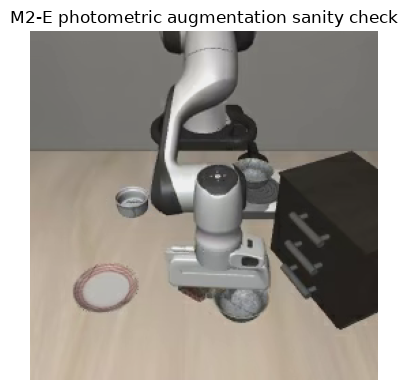

M2-E VISUAL AUGMENTATION SANITY: PASS


In [13]:
visual_check_dataset = LeRobotDataset(
    DATASET_REPO_ID,
    revision=DATASET_REVISION,
    episodes=[train_ids[0]],
    video_backend=VIDEO_BACKEND,
)

sample = visual_check_dataset[len(visual_check_dataset) // 2]
camera_key = list(visual_check_dataset.meta.camera_keys)[0]

raw_image = sample[camera_key]
if not isinstance(raw_image, torch.Tensor):
    raw_image = torch.as_tensor(raw_image)

augmented_image = m2e_image_transform(raw_image)

def image_for_plot(tensor):
    value = tensor.detach().cpu()
    if value.ndim == 3 and value.shape[0] in (1, 3, 4):
        value = value.permute(1, 2, 0)
    return value.numpy()

raw_np = image_for_plot(raw_image)
aug_np = image_for_plot(augmented_image)

assert raw_np.shape == aug_np.shape
assert np.isfinite(aug_np).all()

fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(aug_np)
ax.set_title("M2-E photometric augmentation sanity check")
ax.axis("off")
fig.tight_layout()

figure_path = FIGURES_DIR / "m2e_augmentation_sanity.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

M2E_AUGMENTATION_PASS = True
print("M2-E VISUAL AUGMENTATION SANITY: PASS")

### Five-step M2-E back-propagation smoke test

In [14]:
M2E_SMOKE_DIR = TRAIN_OUTPUT_DIR / "m2e_environment_smoke_seed42"
M2E_SMOKE_LOG = METRICS_DIR / "m2e_environment_smoke_training.log"

m2e_tfs_cli = json.dumps(
    M2E_TRANSFORMS,
    separators=(",", ":"),
)

m2e_smoke_command = [
    *train_entrypoint,
    *common_training_args,
    "--dataset.image_transforms.enable",
    "true",
    "--dataset.image_transforms.max_num_transforms",
    "2",
    "--dataset.image_transforms.random_order",
    "true",
    "--dataset.image_transforms.tfs",
    m2e_tfs_cli,
    "--steps",
    str(SMOKE_STEPS),
    "--batch_size",
    str(SMOKE_BATCH_SIZE),
    "--num_workers",
    "2",
    "--log_freq",
    "1",
    "--save_freq",
    str(SMOKE_STEPS),
    "--output_dir",
    str(M2E_SMOKE_DIR),
    "--job_name",
    "m2e_environment_smoke_seed42",
]

m2e_result = ensure_smoke_run(
    m2e_smoke_command,
    M2E_SMOKE_DIR,
    M2E_SMOKE_LOG,
    SMOKE_STEPS,
)

m2e_metrics_df = m2e_result["metrics"].copy()

display(m2e_metrics_df)

m2e_metrics_df.to_csv(
    METRICS_DIR / "m2e_environment_smoke_metrics.csv",
    index=False,
)

Launching LeRobot training...
INFO 2026-08-24 18:33:43 ot_train.py:442 dataset.num_frames=42156 (42K)
INFO 2026-08-24 18:33:43 ot_train.py:443 dataset.num_episodes=346
INFO 2026-08-24 18:33:43 ot_train.py:447 num_learnable_params=99880992 (100M)
INFO 2026-08-24 18:33:43 ot_train.py:448 num_total_params=450046176 (450M)
Training:  20%|██        | 1/5 [00:07<00:29,  7.40s/step]INFO 2026-08-24 18:33:51 ot_train.py:641 step:1 smpl:1 ep:0 epch:0.00 loss:3.889 grdn:56.638 lr:9.1e-05 updt_s:1.189 data_s:6.207 smp/s:0 mem_gb:1.68 losses_after_forward:3.889 losses_after_in_ep_bound:3.889 losses_after_rm_padding:3.889
INFO 2026-08-24 18:33:51 ot_train.py:641 step:2 smpl:2 ep:0 epch:0.00 loss:1.566 grdn:24.251 lr:6.6e-05 updt_s:0.078 data_s:0.002 smp/s:13 mem_gb:1.68 losses_after_forward:1.566 losses_after_in_ep_bound:1.566 losses_after_rm_padding:1.566
Training:  60%|██████    | 3/5 [00:07<00:03,  1.98s/step]INFO 2026-08-24 18:33:51 ot_train.py:641 step:3 smpl:3 ep:0 epch:0.00 loss:2.569 grdn:26

,step,loss,grad_norm,lr,update_s,data_s,mem_gb
0,1,3.889,56.638,0.000091,1.189,6.207,1.68
1,2,1.566,24.251,0.000066,0.078,0.002,1.68
2,3,2.569,26.741,0.000036,0.073,0.001,1.68
3,4,1.215,30.992,0.000012,0.076,0.001,1.68
4,5,3.197,35.412,0.000003,0.072,0.001,1.68


### Reload and validate the M2-E checkpoint

In [15]:
torch.cuda.empty_cache()

m2e_checkpoint = m2e_result["checkpoint"]

assert (m2e_checkpoint / "config.json").exists()

m2e_policy = (
    SmolVLAPolicy
    .from_pretrained(
        str(m2e_checkpoint),
        local_files_only=True,
    )
    .to(DEVICE)
)

m2e_policy.eval()

m2e_required_steps = set(range(1, SMOKE_STEPS + 1))
m2e_observed_steps = set(m2e_metrics_df["step"].astype(int))

M2E_SMOKE_PASS = bool(
    m2e_required_steps.issubset(m2e_observed_steps)
    and np.isfinite(m2e_metrics_df["loss"]).all()
    and np.isfinite(m2e_metrics_df["grad_norm"]).all()
)

m2e_summary = {
    "status": "PASS" if M2E_SMOKE_PASS else "FAIL",
    "source": m2e_result["source"],
    "checkpoint": str(m2e_checkpoint.relative_to(REPO_ROOT)),
    "steps_verified": len(m2e_required_steps.intersection(m2e_observed_steps)),
    "peak_logged_gpu_memory_gb": float(m2e_metrics_df["mem_gb"].max()),
}

display(pd.DataFrame([m2e_summary]).T.rename(columns={0: "Value"}))

del m2e_policy
torch.cuda.empty_cache()

assert M2E_SMOKE_PASS
print("M2-E BACK-PROPAGATION SMOKE TEST: PASS")

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1947.14it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory


,Value
status,PASS
source,executed
checkpoint,experiments/training/m2e_environment_smoke_see...
steps_verified,5
peak_logged_gpu_memory_gb,1.68


M2-E BACK-PROPAGATION SMOKE TEST: PASS


### Smoke-test loss comparison

,model,step,loss,grad_norm,lr,mem_gb
0,M1,1,3.891,56.689,0.000091,1.68
1,M1,2,1.572,24.327,0.000066,1.68
2,M1,3,2.545,26.349,0.000036,1.68
3,M1,4,1.220,31.083,0.000012,1.68
4,M1,5,3.203,35.469,0.000003,1.68
5,M2-E,1,3.889,56.638,0.000091,1.68
6,M2-E,2,1.566,24.251,0.000066,1.68
7,M2-E,3,2.569,26.741,0.000036,1.68
8,M2-E,4,1.215,30.992,0.000012,1.68
9,M2-E,5,3.197,35.412,0.000003,1.68


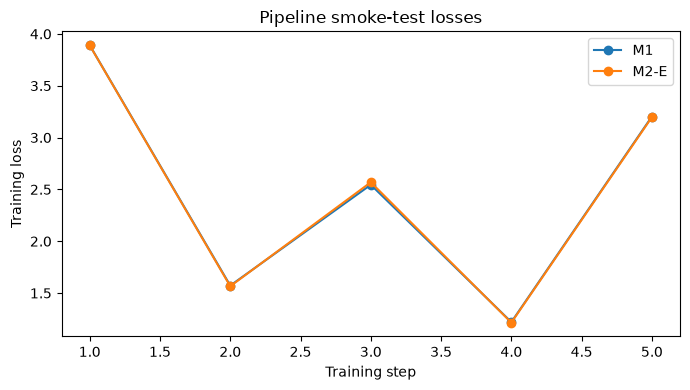

In [16]:
smoke_comparison_df = pd.concat(
    [
        m1_metrics_df.assign(model="M1"),
        m2e_metrics_df.assign(model="M2-E"),
    ],
    ignore_index=True,
)

display(
    smoke_comparison_df[
        ["model", "step", "loss", "grad_norm", "lr", "mem_gb"]
    ]
)

fig, ax = plt.subplots(figsize=(7, 4))

for model_name, group in smoke_comparison_df.groupby("model"):
    ax.plot(
        group["step"],
        group["loss"],
        marker="o",
        label=model_name,
    )

ax.set_xlabel("Training step")
ax.set_ylabel("Training loss")
ax.set_title("Pipeline smoke-test losses")
ax.legend()
fig.tight_layout()

comparison_figure_path = FIGURES_DIR / "smoke_loss_comparison.png"
fig.savefig(comparison_figure_path, dpi=160, bbox_inches="tight")
plt.show()

## 10. M2-L — Deterministic language robustness specification

The language perturbations are **curated and frozen**, not generated randomly during training.

Levels:

- **L0 — Original:** benchmark wording.
- **L1 — Lexical:** synonyms and light wording variation.
- **L2 — Syntactic:** sentence structure changes while preserving the same task.
- **L3 — Compositional:** more substantial meaning-preserving paraphrase; held out from training.

All variants preserve the manipulated object (`black bowl`) and target (`plate`). Spatial/source information is preserved by task-specific wording.

**Training plan:** M2-L and M2-LE use L0/L1/L2. L3 is reserved for held-out language-shift evaluation.

In [17]:
LANGUAGE_VARIANTS = {
    30: {
        "L1": "pick up the black bowl beside the cookie box and put it on the plate",
        "L2": "place the black bowl that is next to the cookie box onto the plate",
        "L3": "move the black bowl positioned beside the cookie box over to the plate",
    },
    31: {
        "L1": "take the black bowl from the top drawer of the wooden cabinet and put it on the plate",
        "L2": "from the wooden cabinet's top drawer, pick up the black bowl and place it on the plate",
        "L3": "retrieve the black bowl stored in the upper drawer of the wooden cabinet, then move it onto the plate",
    },
    32: {
        "L1": "pick up the black bowl sitting on the ramekin and put it on the plate",
        "L2": "place the black bowl that is on the ramekin onto the plate",
        "L3": "move the black bowl resting on top of the ramekin over to the plate",
    },
    33: {
        "L1": "pick up the black bowl sitting on the stove and put it on the plate",
        "L2": "place the black bowl that is on the stove onto the plate",
        "L3": "move the black bowl resting on the stove over to the plate",
    },
    34: {
        "L1": "pick up the black bowl located between the plate and the ramekin and put it on the plate",
        "L2": "place the black bowl that is between the plate and the ramekin onto the plate",
        "L3": "find the black bowl positioned between the plate and ramekin, then move it onto the plate",
    },
    35: {
        "L1": "pick up the black bowl sitting on the cookie box and put it on the plate",
        "L2": "place the black bowl that is on the cookie box onto the plate",
        "L3": "move the black bowl resting on top of the cookie box over to the plate",
    },
    36: {
        "L1": "pick up the black bowl beside the plate and put it on the plate",
        "L2": "place the black bowl that is next to the plate onto the plate",
        "L3": "move the black bowl positioned beside the plate onto the plate",
    },
    37: {
        "L1": "pick up the black bowl beside the ramekin and put it on the plate",
        "L2": "place the black bowl that is next to the ramekin onto the plate",
        "L3": "move the black bowl positioned beside the ramekin over to the plate",
    },
    38: {
        "L1": "pick up the black bowl from the center of the table and put it on the plate",
        "L2": "take the black bowl located at the table center and place it onto the plate",
        "L3": "move the black bowl positioned in the middle of the table onto the plate",
    },
    39: {
        "L1": "pick up the black bowl sitting on the wooden cabinet and put it on the plate",
        "L2": "place the black bowl that is on the wooden cabinet onto the plate",
        "L3": "move the black bowl resting on top of the wooden cabinet over to the plate",
    },
}

original_lookup = {
    int(row["task_index"]): str(row["task_instruction"])
    for _, row in spatial_original_tasks_df.iterrows()
}

assert set(LANGUAGE_VARIANTS) == set(original_lookup)

language_rows = []

for task_id in sorted(original_lookup):
    original = original_lookup[task_id]

    language_rows.append({
        "task_id": task_id,
        "original_instruction": original,
        "level": "L0",
        "augmented_instruction": original,
        "training_seen": True,
        "semantic_review": "PASS",
        "review_note": "Original LIBERO instruction",
    })

    for level in ["L1", "L2", "L3"]:
        augmented = LANGUAGE_VARIANTS[task_id][level]

        language_rows.append({
            "task_id": task_id,
            "original_instruction": original,
            "level": level,
            "augmented_instruction": augmented,
            "training_seen": level in {"L1", "L2"},
            "semantic_review": "PASS",
            "review_note": (
                "Curated meaning-preserving lexical variation"
                if level == "L1"
                else (
                    "Curated meaning-preserving syntactic reformulation"
                    if level == "L2"
                    else "Curated held-out compositional paraphrase"
                )
            ),
        })

language_augmentation_df = pd.DataFrame(language_rows)

assert len(language_augmentation_df) == 40
assert language_augmentation_df["task_id"].nunique() == 10
assert set(language_augmentation_df["level"]) == {"L0", "L1", "L2", "L3"}
assert (language_augmentation_df["semantic_review"] == "PASS").all()
assert language_augmentation_df["augmented_instruction"].str.len().gt(0).all()
assert language_augmentation_df["augmented_instruction"].str.contains(
    "black bowl",
    case=False,
    regex=False,
).all()
assert language_augmentation_df["augmented_instruction"].str.contains(
    "plate",
    case=False,
    regex=False,
).all()

language_augmentation_path = (
    EXPERIMENT_CONFIG_DIR
    / "libero_spatial_language_augmentations_v1.csv"
)

language_augmentation_df.to_csv(
    language_augmentation_path,
    index=False,
)

display(language_augmentation_df)

LANGUAGE_SPEC_PASS = True

print("Language rows :", len(language_augmentation_df))
print("Unique tasks  :", language_augmentation_df["task_id"].nunique())
print("Training levels:", ["L0", "L1", "L2"])
print("Held-out level :", "L3")
print("LANGUAGE ROBUSTNESS SPECIFICATION: PASS")

,task_id,original_instruction,level,augmented_instruction,training_seen,semantic_review,review_note
0,30,pick up the black bowl next to the cookie box ...,L0,pick up the black bowl next to the cookie box ...,True,PASS,Original LIBERO instruction
1,30,pick up the black bowl next to the cookie box ...,L1,pick up the black bowl beside the cookie box a...,True,PASS,Curated meaning-preserving lexical variation
2,30,pick up the black bowl next to the cookie box ...,L2,place the black bowl that is next to the cooki...,True,PASS,Curated meaning-preserving syntactic reformula...
3,30,pick up the black bowl next to the cookie box ...,L3,move the black bowl positioned beside the cook...,False,PASS,Curated held-out compositional paraphrase
4,31,pick up the black bowl in the top drawer of th...,L0,pick up the black bowl in the top drawer of th...,True,PASS,Original LIBERO instruction
5,31,pick up the black bowl in the top drawer of th...,L1,take the black bowl from the top drawer of the...,True,PASS,Curated meaning-preserving lexical variation
6,31,pick up the black bowl in the top drawer of th...,L2,"from the wooden cabinet's top drawer, pick up ...",True,PASS,Curated meaning-preserving syntactic reformula...
7,31,pick up the black bowl in the top drawer of th...,L3,retrieve the black bowl stored in the upper dr...,False,PASS,Curated held-out compositional paraphrase
8,32,pick up the black bowl on the ramekin and plac...,L0,pick up the black bowl on the ramekin and plac...,True,PASS,Original LIBERO instruction
9,32,pick up the black bowl on the ramekin and plac...,L1,pick up the black bowl sitting on the ramekin ...,True,PASS,Curated meaning-preserving lexical variation


Language rows : 40
Unique tasks  : 10
Training levels: ['L0', 'L1', 'L2']
Held-out level : L3
LANGUAGE ROBUSTNESS SPECIFICATION: PASS


## 11. M2-LE combined robustness design

In [18]:
combined_design = {
    "model_id": "M2-LE",
    "initialization": BASE_MODEL_REPO_ID,
    "base_model_revision": BASE_MODEL_REVISION,
    "training_split_sha256": FROZEN_SPLIT_SHA256,
    "language_training_levels": ["L0", "L1", "L2"],
    "language_held_out_level": "L3",
    "environment_augmentation": M2E_TRANSFORMS,
    "principle": (
        "Same initialization, data split and optimization baseline as M1; "
        "only the language/environment robustness factors are changed."
    ),
}

display(pd.DataFrame([combined_design]).T.rename(columns={0: "Value"}))

M2LE_DESIGN_PASS = bool(
    LANGUAGE_SPEC_PASS
    and M2E_AUGMENTATION_PASS
    and M1_SMOKE_PASS
    and M2E_SMOKE_PASS
)

assert M2LE_DESIGN_PASS
print("M2-LE COMBINED DESIGN: PASS")

,Value
model_id,M2-LE
initialization,lerobot/smolvla_base
base_model_revision,c83c3163b8ca9b7e67c509fffd9121e66cb96205
training_split_sha256,0d13554df26d28cfefd58a4d0d873839d54109a4b494f5...
language_training_levels,"[L0, L1, L2]"
language_held_out_level,L3
environment_augmentation,"{'brightness': {'weight': 1.0, 'type': 'ColorJ..."
principle,"Same initialization, data split and optimizati..."


M2-LE COMBINED DESIGN: PASS


## 12. Save experiment manifests

In [19]:
split_manifest = {
    "name": "LIBERO-Spatial episode split v1",
    "seed": SEED,
    "dataset_repo_id": DATASET_REPO_ID,
    "dataset_revision": DATASET_REVISION,
    "split_file": str(frozen_split_path.relative_to(REPO_ROOT)),
    "split_sha256": FROZEN_SPLIT_SHA256,
    "n_train_episodes": len(train_ids),
    "n_validation_episodes": len(validation_ids),
    "episode_overlap": 0,
}

m1_manifest = {
    "model_id": "M1",
    "description": "Standard SmolVLA fine-tuning baseline",
    "base_model_repo_id": BASE_MODEL_REPO_ID,
    "base_model_revision": BASE_MODEL_REVISION,
    "dataset_repo_id": DATASET_REPO_ID,
    "dataset_revision": DATASET_REVISION,
    "split_sha256": FROZEN_SPLIT_SHA256,
    "training_episode_count": len(train_ids),
    "validation_episode_count": len(validation_ids),
    "seed": SEED,
    "smoke_steps": SMOKE_STEPS,
    "smoke_checkpoint": str(m1_result["checkpoint"].relative_to(REPO_ROOT)),
}

m2e_manifest = {
    "model_id": "M2-E",
    "description": "Environmental robustness fine-tuning",
    "base_model_repo_id": BASE_MODEL_REPO_ID,
    "base_model_revision": BASE_MODEL_REVISION,
    "dataset_revision": DATASET_REVISION,
    "split_sha256": FROZEN_SPLIT_SHA256,
    "seed": SEED,
    "environment_augmentation": M2E_TRANSFORMS,
    "smoke_steps": SMOKE_STEPS,
    "smoke_checkpoint": str(m2e_result["checkpoint"].relative_to(REPO_ROOT)),
}

m2l_manifest = {
    "model_id": "M2-L",
    "description": "Language robustness fine-tuning",
    "base_model_repo_id": BASE_MODEL_REPO_ID,
    "base_model_revision": BASE_MODEL_REVISION,
    "dataset_revision": DATASET_REVISION,
    "split_sha256": FROZEN_SPLIT_SHA256,
    "seed": SEED,
    "training_language_levels": ["L0", "L1", "L2"],
    "held_out_language_level": "L3",
    "language_table": str(language_augmentation_path.relative_to(REPO_ROOT)),
}

m2le_manifest = combined_design.copy()

manifest_map = {
    "libero_spatial_split_v1_manifest.json": split_manifest,
    "m1_standard_manifest.json": m1_manifest,
    "m2e_environment_manifest.json": m2e_manifest,
    "m2l_language_manifest.json": m2l_manifest,
    "m2le_combined_manifest.json": m2le_manifest,
}

for filename, content in manifest_map.items():
    with open(EXPERIMENT_CONFIG_DIR / filename, "w") as f:
        json.dump(content, f, indent=2)

MANIFESTS_PASS = all(
    (EXPERIMENT_CONFIG_DIR / filename).exists()
    for filename in manifest_map
)

assert MANIFESTS_PASS

print("Saved manifests:")
for filename in manifest_map:
    print(" -", EXPERIMENT_CONFIG_DIR / filename)

print("EXPERIMENT MANIFESTS: PASS")

Saved manifests:
 - /home/leeming/projects/deep-learning-vla-robustness/configs/experiments/libero_spatial_split_v1_manifest.json
 - /home/leeming/projects/deep-learning-vla-robustness/configs/experiments/m1_standard_manifest.json
 - /home/leeming/projects/deep-learning-vla-robustness/configs/experiments/m2e_environment_manifest.json
 - /home/leeming/projects/deep-learning-vla-robustness/configs/experiments/m2l_language_manifest.json
 - /home/leeming/projects/deep-learning-vla-robustness/configs/experiments/m2le_combined_manifest.json
EXPERIMENT MANIFESTS: PASS


## 13. Experiment matrix

In [20]:
experiment_matrix = pd.DataFrame([
    {
        "model": "M0",
        "initialization": REFERENCE_MODEL_REPO_ID,
        "language_aug": "No",
        "environment_aug": "No",
        "training_language_levels": "Released reference",
        "Notebook 02 status": "Reference reproduced in Notebook 01",
    },
    {
        "model": "M1",
        "initialization": BASE_MODEL_REPO_ID,
        "language_aug": "No",
        "environment_aug": "No",
        "training_language_levels": "L0",
        "Notebook 02 status": "Back-propagation smoke PASS",
    },
    {
        "model": "M2-L",
        "initialization": BASE_MODEL_REPO_ID,
        "language_aug": "Yes",
        "environment_aug": "No",
        "training_language_levels": "L0 + L1 + L2; L3 held out",
        "Notebook 02 status": "Perturbation specification PASS",
    },
    {
        "model": "M2-E",
        "initialization": BASE_MODEL_REPO_ID,
        "language_aug": "No",
        "environment_aug": "Yes",
        "training_language_levels": "L0",
        "Notebook 02 status": "Back-propagation smoke PASS",
    },
    {
        "model": "M2-LE",
        "initialization": BASE_MODEL_REPO_ID,
        "language_aug": "Yes",
        "environment_aug": "Yes",
        "training_language_levels": "L0 + L1 + L2; L3 held out",
        "Notebook 02 status": "Combined design PASS",
    },
])

display(experiment_matrix)

experiment_matrix.to_csv(
    METRICS_DIR / "experiment_matrix.csv",
    index=False,
)

,model,initialization,language_aug,environment_aug,training_language_levels,Notebook 02 status
0,M0,lerobot/smolvla_libero,No,No,Released reference,Reference reproduced in Notebook 01
1,M1,lerobot/smolvla_base,No,No,L0,Back-propagation smoke PASS
2,M2-L,lerobot/smolvla_base,Yes,No,L0 + L1 + L2; L3 held out,Perturbation specification PASS
3,M2-E,lerobot/smolvla_base,No,Yes,L0,Back-propagation smoke PASS
4,M2-LE,lerobot/smolvla_base,Yes,Yes,L0 + L1 + L2; L3 held out,Combined design PASS


## 14. Final reproducibility and notebook status

In [21]:
final_checks = {
    "Prior dataset audit":
        bool(prior_gate["Notebook 00 dataset audit"]),
    "G0 closed-loop compatibility":
        bool(prior_gate["Notebook 01 G0 closed-loop compatibility"]),
    "Frozen split integrity":
        (
            len(train_ids) == 346
            and len(validation_ids) == 86
            and set(train_ids).isdisjoint(validation_ids)
        ),
    "All 10 tasks in train and validation":
        (
            train_task_ids == all_task_ids
            and validation_task_ids == all_task_ids
            and len(all_task_ids) == 10
        ),
    "LeRobot frozen subset consumption":
        (
            train_subset.num_episodes == len(train_ids)
            and validation_subset.num_episodes == len(validation_ids)
        ),
    "Base model revision pinned":
        bool(BASE_MODEL_REVISION),
    "M1 back-propagation smoke":
        M1_SMOKE_PASS,
    "M1 checkpoint reload":
        M1_SMOKE_PASS,
    "M2-E augmentation sanity":
        M2E_AUGMENTATION_PASS,
    "M2-E back-propagation smoke":
        M2E_SMOKE_PASS,
    "Language perturbation specification":
        LANGUAGE_SPEC_PASS,
    "M2-LE combined design":
        M2LE_DESIGN_PASS,
    "Experiment manifests":
        MANIFESTS_PASS,
}

final_status_df = pd.DataFrame(
    [
        {
            "check": check,
            "status": "PASS" if passed else "FAIL",
        }
        for check, passed in final_checks.items()
    ]
)

display(final_status_df)

NOTEBOOK_02_PASS = bool(all(final_checks.values()))

notebook02_summary = {
    "notebook": "02_robustness_training",
    "status": "PASS" if NOTEBOOK_02_PASS else "FAIL",
    "project_git_sha": PROJECT_GIT_SHA,
    "dataset_repo_id": DATASET_REPO_ID,
    "dataset_revision": DATASET_REVISION,
    "reference_model_repo_id": REFERENCE_MODEL_REPO_ID,
    "reference_model_revision": REFERENCE_MODEL_REVISION,
    "base_model_repo_id": BASE_MODEL_REPO_ID,
    "base_model_revision": BASE_MODEL_REVISION,
    "split_file": str(frozen_split_path.relative_to(REPO_ROOT)),
    "split_sha256": FROZEN_SPLIT_SHA256,
    "n_train_episodes": len(train_ids),
    "n_validation_episodes": len(validation_ids),
    "m1_smoke_checkpoint": str(m1_checkpoint.relative_to(REPO_ROOT)),
    "m2e_smoke_checkpoint": str(m2e_checkpoint.relative_to(REPO_ROOT)),
    "language_table": str(language_augmentation_path.relative_to(REPO_ROOT)),
    "language_training_levels": ["L0", "L1", "L2"],
    "language_held_out_level": "L3",
    "checks": final_checks,
}

summary_path = METRICS_DIR / "notebook02_summary.json"

with open(summary_path, "w") as f:
    json.dump(notebook02_summary, f, indent=2)

print("=" * 64)
print("NOTEBOOK 02 — FINAL STATUS")
print("=" * 64)

for check, passed in final_checks.items():
    print(f"{check:<46} {'PASS' if passed else 'FAIL'}")

print("-" * 64)
print(f"{'NOTEBOOK 02 STATUS':<46} {'PASS' if NOTEBOOK_02_PASS else 'FAIL'}")
print("-" * 64)

assert NOTEBOOK_02_PASS

print()
print("Ready for Notebook 03:")
print("Hyperparameter tuning and final multi-seed training.")
print()
print("Summary saved:", summary_path)

,check,status
0,Prior dataset audit,PASS
1,G0 closed-loop compatibility,PASS
2,Frozen split integrity,PASS
3,All 10 tasks in train and validation,PASS
4,LeRobot frozen subset consumption,PASS
5,Base model revision pinned,PASS
6,M1 back-propagation smoke,PASS
7,M1 checkpoint reload,PASS
8,M2-E augmentation sanity,PASS
9,M2-E back-propagation smoke,PASS


NOTEBOOK 02 — FINAL STATUS
Prior dataset audit                            PASS
G0 closed-loop compatibility                   PASS
Frozen split integrity                         PASS
All 10 tasks in train and validation           PASS
LeRobot frozen subset consumption              PASS
Base model revision pinned                     PASS
M1 back-propagation smoke                      PASS
M1 checkpoint reload                           PASS
M2-E augmentation sanity                       PASS
M2-E back-propagation smoke                    PASS
Language perturbation specification            PASS
M2-LE combined design                          PASS
Experiment manifests                           PASS
----------------------------------------------------------------
NOTEBOOK 02 STATUS                             PASS
----------------------------------------------------------------

Ready for Notebook 03:
Hyperparameter tuning and final multi-seed training.

Summary saved: /home/leeming/projects

## Interpretation

Notebook 02 demonstrates that the proposed robustness experiment is technically viable and controlled:

- the train/validation split is frozen and leakage-free,
- every trainable variant uses the same pinned SmolVLA base initialization,
- M1 performs real gradient updates and produces a reloadable checkpoint,
- M2-E performs real gradient updates with controlled photometric augmentation,
- the complete L0–L3 language perturbation set is deterministic and auditable,
- L3 remains held out from training,
- all experiment definitions are persisted as reproducibility manifests.

The five-step losses should **not** be interpreted as comparative model performance. They only establish that each intended training pathway executes correctly. Notebook 03 will determine meaningful training budgets, tune a small controlled hyperparameter set, and conduct the final multi-seed training runs.